# Análise Comparativa de Modelos — AlignFit

## Modelos comparados
| Modelo | Tipo | Característica principal |
|--------|------|-------------------------|
| **XGBoost** | Ensemble (Gradient Boosting) | Árvores sequenciais com regularização |
| **KNN** | Instance-based | Classificação por vizinhos mais próximos |
| **SVM** | Kernel-based | Separação por hiperplano em espaço de alta dimensão |
| **Decision Tree** | Árvore de decisão | Particionamento recursivo por atributos |
| **MLP (Softmax)** | Rede neural | Camadas densas com saída softmax (probabilidade por classe) |

## Métricas avaliadas
- Accuracy, Precision, Recall, F1-Score
- Tempo de treinamento e inferência
- Cross-validation (5-fold stratified)


In [1]:
# =========================================================
# IMPORTS
# =========================================================

import pandas as pd
import numpy as np
import time
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

np.random.seed(42)
tf.random.set_seed(42)

print("Bibliotecas carregadas com sucesso!")


I0000 00:00:1787270865.447583   14849 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787270865.490010   14849 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787270866.763997   14849 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Bibliotecas carregadas com sucesso!


In [2]:
# =========================================================
# CARREGAR DATASET
# =========================================================

DATASET_PATH = "../datasets/raw-dataset.csv"

df = pd.read_csv(DATASET_PATH, sep=",")

print(f"Dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"\nDistribuição do alvo (tipo_exercicio):")
print(df['tipo_exercicio'].value_counts())
print(f"\nTotal de vídeos: {df['video'].nunique()}")


Dataset carregado: 19868 linhas x 41 colunas

Distribuição do alvo (tipo_exercicio):
tipo_exercicio
elevacao_lateral    6908
agachamento         4723
biceps              4666
desenvolvimento     3571
Name: count, dtype: int64

Total de vídeos: 537


In [3]:
# =========================================================
# PREPARAÇÃO DOS DADOS
# Mesma engenharia de atributos usada no modelo de produção:
# - Agrupar por vídeo
# - Extrair: média, desvio padrão, mínimo, máximo
# =========================================================

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["tipo_exercicio"])

feature_columns = [col for col in df.columns if col.endswith("_x") or col.endswith("_y")]
print(f"Features de keypoints: {len(feature_columns)} colunas")

X = []
y = []

for video_name, group in df.groupby("video"):
    features = []
    features.extend(group[feature_columns].mean().tolist())       # Média
    features.extend(group[feature_columns].std().fillna(0).tolist())  # Desvio padrão
    features.extend(group[feature_columns].min().tolist())        # Mínimo
    features.extend(group[feature_columns].max().tolist())        # Máximo
    X.append(features)
    y.append(group["label"].iloc[0])

X = np.array(X)
y = np.array(y)

num_classes = len(label_encoder.classes_)

print(f"\nDataset agregado por vídeo:")
print(f"  X shape: {X.shape} ({X.shape[0]} vídeos, {X.shape[1]} features)")
print(f"  y shape: {y.shape}")
print(f"  Classes: {label_encoder.classes_}")


Features de keypoints: 34 colunas



Dataset agregado por vídeo:
  X shape: (537, 136) (537 vídeos, 136 features)
  y shape: (537,)
  Classes: ['agachamento' 'biceps' 'desenvolvimento' 'elevacao_lateral']


In [4]:
# =========================================================
# SPLIT TREINO/TESTE
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")

# Scaler para KNN, SVM e MLP (sensíveis à escala)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Treino: 429 amostras
Teste:  108 amostras


In [5]:
# =========================================================
# DEFINIÇÃO DOS MODELOS SCIKIT-LEARN / XGBOOST
# (a MLP com Softmax é tratada à parte, pois usa Keras)
# =========================================================

models = {
    "XGBoost": {
        "model": XGBClassifier(
            n_estimators=300,
            max_depth=8,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),
        "needs_scaling": False
    },
    "KNN (k=5)": {
        "model": KNeighborsClassifier(n_neighbors=5),
        "needs_scaling": True
    },
    "SVM (RBF)": {
        "model": SVC(kernel='rbf', C=1.0, random_state=42),
        "needs_scaling": True
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(
            max_depth=10,
            random_state=42
        ),
        "needs_scaling": False
    }
}

print("Modelos configurados:")
for name in models:
    print(f"  ✓ {name}")
print("  ✓ MLP (Softmax)  [tratada separadamente, ver próxima seção]")


Modelos configurados:
  ✓ XGBoost
  ✓ KNN (k=5)
  ✓ SVM (RBF)
  ✓ Decision Tree
  ✓ MLP (Softmax)  [tratada separadamente, ver próxima seção]


In [6]:
# =========================================================
# TREINAMENTO E AVALIAÇÃO (scikit-learn / XGBoost)
# =========================================================

results = []

print("=" * 70)
print("TREINAMENTO E AVALIAÇÃO DOS MODELOS")
print("=" * 70)

for name, config in models.items():
    print(f"\n{'─' * 70}")
    print(f"▶ {name}")
    print(f"{'─' * 70}")

    model = config["model"]
    use_scaled = config["needs_scaling"]

    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test

    # --- Tempo de treinamento ---
    start_train = time.time()
    model.fit(X_tr, y_train)
    train_time = time.time() - start_train

    # --- Tempo de inferência ---
    start_pred = time.time()
    y_pred = model.predict(X_te)
    pred_time = time.time() - start_pred

    # --- Métricas ---
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')

    # --- Cross-validation manual (StratifiedKFold) ---
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    X_cv = scaler.fit_transform(X) if use_scaled else X

    cv_accs = []
    for train_idx, val_idx in cv.split(X_cv, y):
        fold_model = config["model"].__class__(**config["model"].get_params())
        fold_model.fit(X_cv[train_idx], y[train_idx])
        fold_pred = fold_model.predict(X_cv[val_idx])
        cv_accs.append(accuracy_score(y[val_idx], fold_pred))
    cv_accs = np.array(cv_accs)

    results.append({
        "Modelo": name,
        "Accuracy": acc,
        "F1-Score": f1,
        "CV Mean": cv_accs.mean(),
        "CV Std": cv_accs.std(),
        "Tempo Treino (s)": train_time,
        "Tempo Inferência (ms)": pred_time * 1000
    })

    print(f"\n  Accuracy:          {acc:.4f}")
    print(f"  F1-Score:          {f1:.4f}")
    print(f"  CV (5-fold):       {cv_accs.mean():.4f} ± {cv_accs.std():.4f}")
    print(f"  Tempo treino:      {train_time:.3f}s")
    print(f"  Tempo inferência:  {pred_time*1000:.2f}ms")
    print(f"\n  Classification Report:")
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


TREINAMENTO E AVALIAÇÃO DOS MODELOS

──────────────────────────────────────────────────────────────────────
▶ XGBoost
──────────────────────────────────────────────────────────────────────



  Accuracy:          0.9167
  F1-Score:          0.9174
  CV (5-fold):       0.9441 ± 0.0196
  Tempo treino:      5.120s
  Tempo inferência:  3.11ms

  Classification Report:
                  precision    recall  f1-score   support

     agachamento       1.00      0.92      0.96        24
          biceps       0.88      0.95      0.91        37
 desenvolvimento       1.00      0.85      0.92        20
elevacao_lateral       0.86      0.93      0.89        27

        accuracy                           0.92       108
       macro avg       0.93      0.91      0.92       108
    weighted avg       0.92      0.92      0.92       108


──────────────────────────────────────────────────────────────────────
▶ KNN (k=5)
──────────────────────────────────────────────────────────────────────

  Accuracy:          0.8426
  F1-Score:          0.8441
  CV (5-fold):       0.8344 ± 0.0395
  Tempo treino:      0.001s
  Tempo inferência:  17.25ms

  Classification Report:
                  precisi


  Accuracy:          0.8611
  F1-Score:          0.8559
  CV (5-fold):       0.8529 ± 0.0342
  Tempo treino:      0.022s
  Tempo inferência:  0.20ms

  Classification Report:
                  precision    recall  f1-score   support

     agachamento       0.96      0.96      0.96        24
          biceps       0.86      0.97      0.91        37
 desenvolvimento       0.81      0.85      0.83        20
elevacao_lateral       0.81      0.63      0.71        27

        accuracy                           0.86       108
       macro avg       0.86      0.85      0.85       108
    weighted avg       0.86      0.86      0.86       108



## MLP com Softmax

Tratada em separado porque o Keras não segue a API `fit`/`predict` do scikit-learn
usada no loop acima (precisa de `epochs`, `batch_size`, etc). Para manter a
comparação justa, aplicamos o mesmo split, o mesmo scaler e o mesmo esquema de
cross-validation (StratifiedKFold 5-fold) usados nos demais modelos.


In [7]:
# =========================================================
# MLP COM SOFTMAX — treino no split de treino/teste
# =========================================================

def build_mlp(input_dim, num_classes):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(units=128, activation="relu"),
        Dense(units=64, activation="relu"),
        Dense(units=32, activation="relu"),
        Dense(units=num_classes, activation="softmax"),
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

print(f"\n{'─' * 70}")
print("▶ MLP (Softmax)")
print(f"{'─' * 70}")

start_train = time.time()
mlp = build_mlp(X_train_scaled.shape[1], num_classes)
mlp.fit(
    X_train_scaled, y_train,
    validation_split=0.15,
    epochs=80,
    batch_size=16,
    verbose=0,
)
train_time = time.time() - start_train

start_pred = time.time()
y_pred = np.argmax(mlp.predict(X_test_scaled, verbose=0), axis=1)
pred_time = time.time() - start_pred

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print(f"\n  Accuracy:          {acc:.4f}")
print(f"  F1-Score:          {f1:.4f}")
print(f"  Tempo treino:      {train_time:.3f}s")
print(f"  Tempo inferência:  {pred_time*1000:.2f}ms")
print(f"\n  Classification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))



──────────────────────────────────────────────────────────────────────
▶ MLP (Softmax)
──────────────────────────────────────────────────────────────────────



  Accuracy:          0.9444
  F1-Score:          0.9445
  Tempo treino:      14.222s
  Tempo inferência:  185.44ms

  Classification Report:
                  precision    recall  f1-score   support

     agachamento       0.96      1.00      0.98        24
          biceps       0.95      0.95      0.95        37
 desenvolvimento       1.00      0.90      0.95        20
elevacao_lateral       0.89      0.93      0.91        27

        accuracy                           0.94       108
       macro avg       0.95      0.94      0.95       108
    weighted avg       0.95      0.94      0.94       108



In [8]:
# =========================================================
# MLP COM SOFTMAX — cross-validation manual (5-fold)
# =========================================================

X_cv = scaler.fit_transform(X)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_accs = []
for fold_id, (train_idx, val_idx) in enumerate(cv.split(X_cv, y), start=1):
    fold_model = build_mlp(X_cv.shape[1], num_classes)
    fold_model.fit(
        X_cv[train_idx], y[train_idx],
        epochs=80,
        batch_size=16,
        verbose=0,
    )
    fold_pred = np.argmax(fold_model.predict(X_cv[val_idx], verbose=0), axis=1)
    fold_acc = accuracy_score(y[val_idx], fold_pred)
    cv_accs.append(fold_acc)
    print(f"  Fold {fold_id}: accuracy = {fold_acc:.4f}")

cv_accs = np.array(cv_accs)
print(f"\nCV (5-fold): {cv_accs.mean():.4f} ± {cv_accs.std():.4f}")

results.append({
    "Modelo": "MLP (Softmax)",
    "Accuracy": acc,
    "F1-Score": f1,
    "CV Mean": cv_accs.mean(),
    "CV Std": cv_accs.std(),
    "Tempo Treino (s)": train_time,
    "Tempo Inferência (ms)": pred_time * 1000
})


  Fold 1: accuracy = 0.9352


  Fold 2: accuracy = 0.8796


  Fold 3: accuracy = 0.9720


  Fold 4: accuracy = 0.9626


  Fold 5: accuracy = 0.9720

CV (5-fold): 0.9443 ± 0.0350


In [9]:
# =========================================================
# TABELA COMPARATIVA
# =========================================================

df_results = pd.DataFrame(results)
df_results = df_results.sort_values("Accuracy", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("TABELA COMPARATIVA")
print("=" * 70 + "\n")

display(df_results.style.highlight_max(
    subset=["Accuracy", "F1-Score", "CV Mean"],
    color="lightgreen"
).highlight_min(
    subset=["Tempo Treino (s)", "Tempo Inferência (ms)"],
    color="lightyellow"
).format({
    "Accuracy": "{:.4f}",
    "F1-Score": "{:.4f}",
    "CV Mean": "{:.4f}",
    "CV Std": "{:.4f}",
    "Tempo Treino (s)": "{:.3f}",
    "Tempo Inferência (ms)": "{:.2f}"
}))



TABELA COMPARATIVA



,Modelo,Accuracy,F1-Score,CV Mean,CV Std,Tempo Treino (s),Tempo Inferência (ms)
0,MLP (Softmax),0.9444,0.9445,0.9443,0.0350,14.222,185.44
1,XGBoost,0.9167,0.9174,0.9441,0.0196,5.120,3.11
2,SVM (RBF),0.9167,0.9163,0.9162,0.0210,0.008,4.34
3,Decision Tree,0.8611,0.8559,0.8529,0.0342,0.022,0.20
4,KNN (k=5),0.8426,0.8441,0.8344,0.0395,0.001,17.25


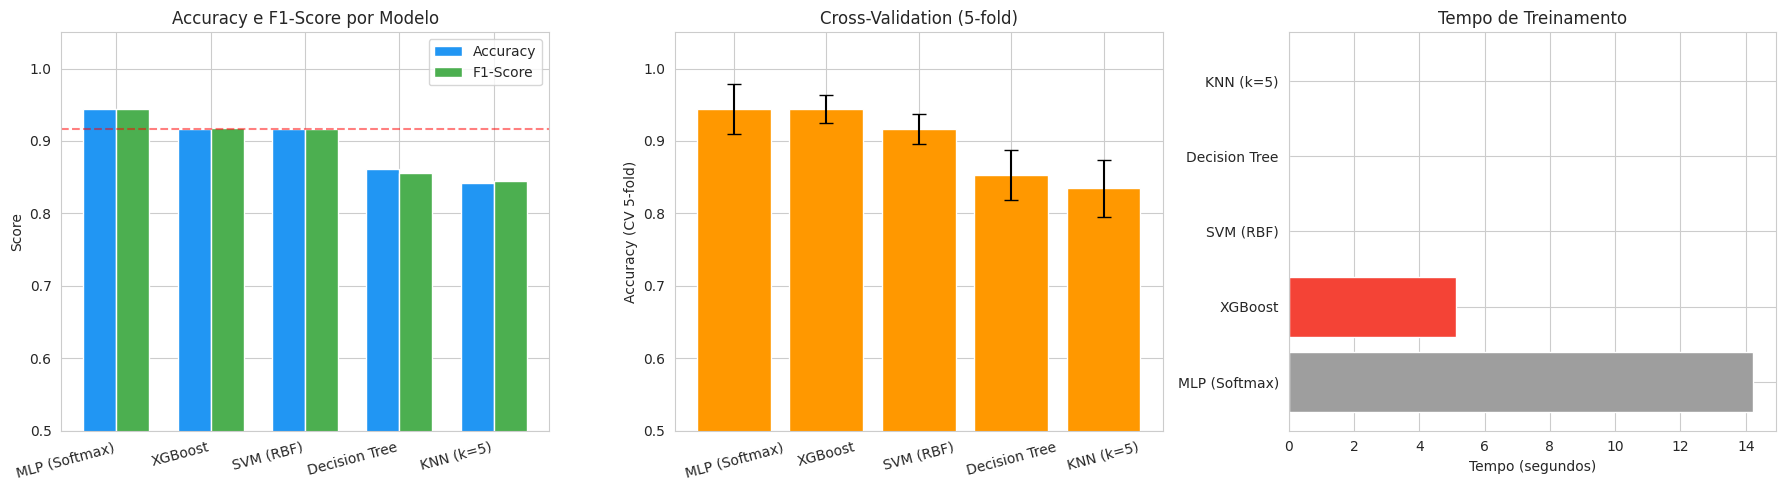


📊 Gráfico salvo: comparativo_modelos.png


In [10]:
# =========================================================
# GRÁFICO 1: COMPARAÇÃO DE ACCURACY E F1-SCORE
# =========================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x = range(len(df_results))
width = 0.35

axes[0].bar([i - width/2 for i in x], df_results["Accuracy"], width, label="Accuracy", color="#2196F3")
axes[0].bar([i + width/2 for i in x], df_results["F1-Score"], width, label="F1-Score", color="#4CAF50")
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_results["Modelo"], rotation=15, ha='right')
axes[0].set_ylim(0.5, 1.05)
axes[0].set_ylabel("Score")
axes[0].set_title("Accuracy e F1-Score por Modelo")
axes[0].legend()
axes[0].axhline(y=df_results[df_results['Modelo']=='XGBoost']['Accuracy'].values[0],
               color='red', linestyle='--', alpha=0.5, label='XGBoost baseline')

axes[1].bar(df_results["Modelo"], df_results["CV Mean"],
           yerr=df_results["CV Std"], color="#FF9800", capsize=5)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_ylabel("Accuracy (CV 5-fold)")
axes[1].set_title("Cross-Validation (5-fold)")
axes[1].tick_params(axis='x', rotation=15)

colors = ['#F44336' if m == 'XGBoost' else '#9E9E9E' for m in df_results["Modelo"]]
axes[2].barh(df_results["Modelo"], df_results["Tempo Treino (s)"], color=colors)
axes[2].set_xlabel("Tempo (segundos)")
axes[2].set_title("Tempo de Treinamento")

plt.tight_layout()
plt.savefig("comparativo_modelos.png", dpi=150, bbox_inches='tight')
plt.show()
print("\n📊 Gráfico salvo: comparativo_modelos.png")


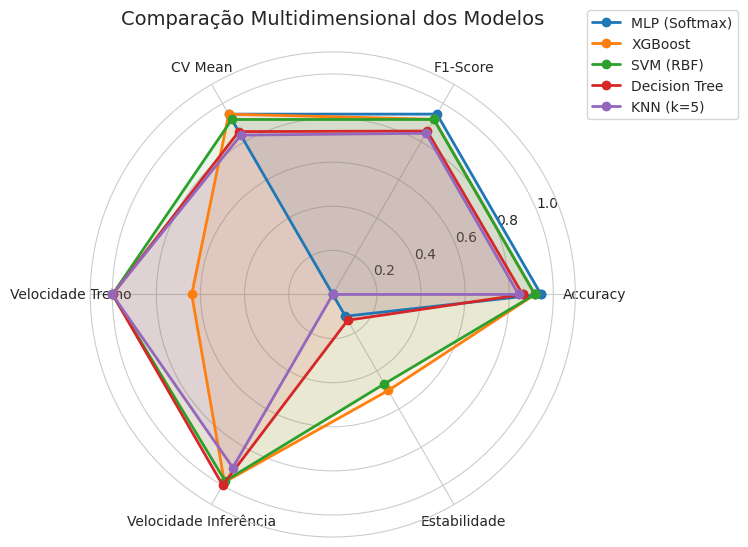


📊 Gráfico salvo: radar_comparativo.png


In [11]:
# =========================================================
# GRÁFICO 2: RADAR CHART (VISÃO HOLÍSTICA)
# =========================================================

metrics_radar = df_results[["Accuracy", "F1-Score", "CV Mean"]].copy()

max_train = df_results["Tempo Treino (s)"].max()
metrics_radar["Velocidade Treino"] = 1 - (df_results["Tempo Treino (s)"] / max_train)

max_pred = df_results["Tempo Inferência (ms)"].max()
metrics_radar["Velocidade Inferência"] = 1 - (df_results["Tempo Inferência (ms)"] / max_pred)

max_std = df_results["CV Std"].max()
metrics_radar["Estabilidade"] = 1 - (df_results["CV Std"] / max_std) if max_std > 0 else 1

categories = list(metrics_radar.columns)
N = len(categories)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

# Paleta gerada dinamicamente para suportar qualquer número de modelos
cmap = plt.get_cmap("tab10")
colors_radar = [cmap(i) for i in range(len(df_results))]

for idx, row in df_results.iterrows():
    values = metrics_radar.iloc[idx].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=row["Modelo"], color=colors_radar[idx])
    ax.fill(angles, values, alpha=0.1, color=colors_radar[idx])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylim(0, 1.1)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
ax.set_title("Comparação Multidimensional dos Modelos", fontsize=14, pad=20)

plt.tight_layout()
plt.savefig("radar_comparativo.png", dpi=150, bbox_inches='tight')
plt.show()
print("\n📊 Gráfico salvo: radar_comparativo.png")


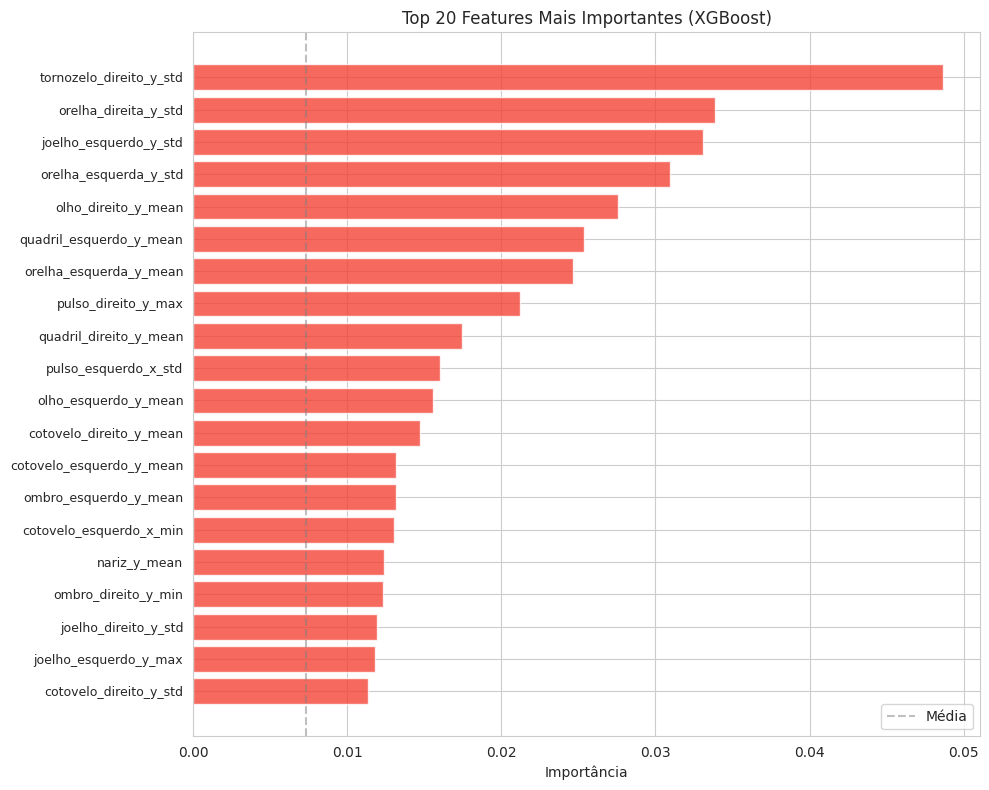


📊 Gráfico salvo: feature_importance_xgboost.png


In [12]:
# =========================================================
# GRÁFICO 3: FEATURE IMPORTANCE (XGBoost)
# Vantagem exclusiva do XGBoost: interpretabilidade
# =========================================================

xgb_model = models["XGBoost"]["model"]

feat_names = (
    [f"{c}_mean" for c in feature_columns] +
    [f"{c}_std" for c in feature_columns] +
    [f"{c}_min" for c in feature_columns] +
    [f"{c}_max" for c in feature_columns]
)

importances = xgb_model.feature_importances_
top_n = 20

top_idx = np.argsort(importances)[-top_n:][::-1]
top_features = [feat_names[i] if i < len(feat_names) else f"feat_{i}" for i in top_idx]
top_values = importances[top_idx]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(top_n), top_values[::-1], color='#F44336', alpha=0.8)
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features[::-1], fontsize=9)
ax.set_xlabel("Importância")
ax.set_title(f"Top {top_n} Features Mais Importantes (XGBoost)")
ax.axvline(x=np.mean(importances), color='gray', linestyle='--', alpha=0.5, label='Média')
ax.legend()

plt.tight_layout()
plt.savefig("feature_importance_xgboost.png", dpi=150, bbox_inches='tight')
plt.show()
print("\n📊 Gráfico salvo: feature_importance_xgboost.png")


In [13]:
# =========================================================
# CONCLUSÃO E JUSTIFICATIVA
# =========================================================

best_model = df_results.iloc[0]["Modelo"]
best_acc = df_results.iloc[0]["Accuracy"]
best_f1 = df_results.iloc[0]["F1-Score"]
best_cv = df_results.iloc[0]["CV Mean"]

fastest_train = df_results.sort_values("Tempo Treino (s)").iloc[0]
fastest_infer = df_results.sort_values("Tempo Inferência (ms)").iloc[0]
most_stable = df_results.sort_values("CV Std").iloc[0]

print("=" * 70)
print("CONCLUSÃO DA ANÁLISE COMPARATIVA")
print("=" * 70)

print(f"\n🏆 Melhor modelo por Accuracy:      {best_model} ({best_acc:.4f})")
print(f"🏆 Melhor modelo por CV (5-fold):    {df_results.sort_values('CV Mean', ascending=False).iloc[0]['Modelo']} "
      f"({df_results.sort_values('CV Mean', ascending=False).iloc[0]['CV Mean']:.4f})")
print(f"⚡ Treino mais rápido:                {fastest_train['Modelo']} ({fastest_train['Tempo Treino (s)']:.3f}s)")
print(f"⚡ Inferência mais rápida:            {fastest_infer['Modelo']} ({fastest_infer['Tempo Inferência (ms)']:.2f}ms)")
print(f"📐 Mais estável entre folds:          {most_stable['Modelo']} (std={most_stable['CV Std']:.4f})")

print("\n" + "-" * 70)
print("\n📊 RESULTADOS DE TODOS OS MODELOS:\n")
for _, row in df_results.iterrows():
    print(f"  {row['Modelo']:<18} Accuracy={row['Accuracy']:.4f}  F1={row['F1-Score']:.4f}  "
          f"CV={row['CV Mean']:.4f}±{row['CV Std']:.4f}  "
          f"Treino={row['Tempo Treino (s)']:.3f}s  Inferência={row['Tempo Inferência (ms)']:.2f}ms")

print("\n" + "-" * 70)
print("\n📝 PONTOS PARA DISCUTIR NO TCC (independente de qual modelo vença aqui):\n")
print("1. DATASET PEQUENO:")
print("   Com poucas centenas de vídeos, o resultado da MLP pode variar bastante")
print("   entre execuções (inicialização aleatória dos pesos, ordem dos batches).")
print("   O desvio padrão do CV (5-fold) de cada modelo ajuda a avaliar isso —")
print("   compare a coluna 'CV Std' entre os modelos, não só a Accuracy pontual.")
print()
print("2. CUSTO DE TREINAMENTO E INFERÊNCIA:")
print("   Modelos de árvore/kernel costumam treinar mais rápido; a MLP tende a")
print("   ter inferência mais lenta (chamada ao TensorFlow) — relevante se o uso")
print("   final for em tempo real ou em ambiente com poucos recursos (ex: serverless).")
print()
print("3. INTERPRETABILIDADE:")
print("   XGBoost e Decision Tree oferecem feature importance nativa. A MLP,")
print("   como caixa-preta, exigiria técnicas extras (ex: SHAP) para o mesmo tipo")
print("   de explicação — relevante para justificar decisões num app de fitness.")
print()
print("4. ESCOLHA FINAL:")
print("   A decisão de qual modelo colocar em produção não deve se basear só na")
print("   accuracy do split de teste (que pode variar com o random_state). Use a")
print("   média e o desvio do CV de 5 folds como critério mais robusto, e pese")
print("   também custo computacional e necessidade de interpretabilidade.")
print()
print("=" * 70)


CONCLUSÃO DA ANÁLISE COMPARATIVA

🏆 Melhor modelo por Accuracy:      MLP (Softmax) (0.9444)
🏆 Melhor modelo por CV (5-fold):    MLP (Softmax) (0.9443)
⚡ Treino mais rápido:                KNN (k=5) (0.001s)
⚡ Inferência mais rápida:            Decision Tree (0.20ms)
📐 Mais estável entre folds:          XGBoost (std=0.0196)

----------------------------------------------------------------------

📊 RESULTADOS DE TODOS OS MODELOS:

  MLP (Softmax)      Accuracy=0.9444  F1=0.9445  CV=0.9443±0.0350  Treino=14.222s  Inferência=185.44ms
  XGBoost            Accuracy=0.9167  F1=0.9174  CV=0.9441±0.0196  Treino=5.120s  Inferência=3.11ms
  SVM (RBF)          Accuracy=0.9167  F1=0.9163  CV=0.9162±0.0210  Treino=0.008s  Inferência=4.34ms
  Decision Tree      Accuracy=0.8611  F1=0.8559  CV=0.8529±0.0342  Treino=0.022s  Inferência=0.20ms
  KNN (k=5)          Accuracy=0.8426  F1=0.8441  CV=0.8344±0.0395  Treino=0.001s  Inferência=17.25ms

--------------------------------------------------------------